In [5]:
import numpy as np
import matplotlib.pyplot as plt

d = np.load('fixed_gauss5.npz', allow_pickle=True)
t         = d['t']
k_params  = d['k_params']    # (n, 3)  — [lin_seg3, gauss_seg1, gauss_seg2]
comp_pos  = d['comp_pos']    # (n, 3, 3) — FK x/y/z at each VC s_param
goal      = d['goal']        # (n, 3, 3) — reference positions
names     = [str(s) for s in d['comp_names']]
s_params  = list(d['comp_s_params'])

print('Components:', list(zip(names, [f's={s:.3f}' for s in s_params])))
print('Duration:  ', f'{t[-1]:.1f} s')

# Find the gaussian strength drop (700->0 and 600->0)
gauss_k  = k_params[:, 1]
diff_k   = np.diff(gauss_k)
drop_idx = int(np.where(diff_k < -50)[0][0])
drop_t   = t[drop_idx]
print(f'\nGauss strength drop at t = {drop_t:.2f} s  (idx={drop_idx})')
print(f'  k before: gauss1={k_params[drop_idx, 1]:.0f}  gauss2={k_params[drop_idx, 2]:.0f}')
print(f'  k after:  gauss1={k_params[drop_idx+1, 1]:.0f}  gauss2={k_params[drop_idx+1, 2]:.0f}')

WIN = 5.0
mask_before = (t >= drop_t - WIN) & (t < drop_t)
mask_after  = (t >  drop_t)       & (t <= drop_t + WIN)
print(f'\nBefore window: {mask_before.sum()} samples  [{t[mask_before][0]:.2f}, {t[mask_before][-1]:.2f}] s')
print(f'After  window: {mask_after.sum()} samples  [{t[mask_after][0]:.2f}, {t[mask_after][-1]:.2f}] s')

Components: [('lin_seg3', 's=1.000'), ('gauss_seg1', 's=0.333'), ('gauss_seg2', 's=0.667')]
Duration:   63.9 s

Gauss strength drop at t = 53.40 s  (idx=16598)
  k before: gauss1=700  gauss2=600
  k after:  gauss1=0  gauss2=0

Before window: 1649 samples  [48.40, 53.39] s
After  window: 649 samples  [56.43, 58.40] s


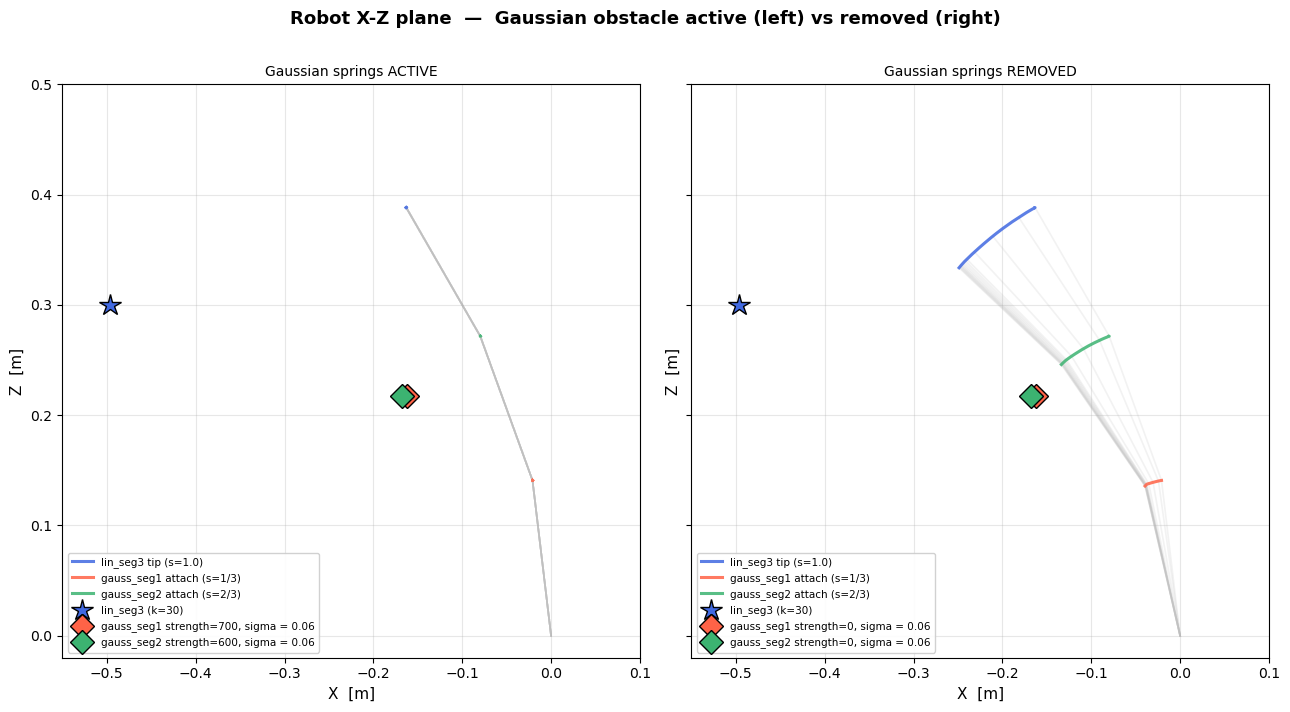

Saved -> fixed_gauss5_xz.png


In [10]:
# X-Z plane visualisation: obstacle active (left) vs removed (right)

N_SNAPSHOTS    = 15
BACKBONE_ALPHA = 0.20
BACKBONE_COLOR = 'silver'
TRAJ_ALPHA     = 0.85
VC_COLORS = ['royalblue', 'tomato', 'mediumseagreen']  # lin, gauss1, gauss2

fig, axes = plt.subplots(1, 2, figsize=(13, 7), sharey=True)
fig.suptitle(
    'Robot X-Z plane  —  Gaussian obstacle active (left) vs removed (right)',
    fontsize=13, fontweight='bold', y=1.01
)

panel_data = [
    (axes[0], mask_before, 'Gaussian springs ACTIVE'),
    (axes[1], mask_after,  'Gaussian springs REMOVED'),
]

for ax, mask, title in panel_data:
    cp  = comp_pos[mask]    # (m, 3, 3)
    gl  = goal[mask]        # (m, 3, 3)
    m   = len(cp)

    # Backbone snapshots: origin -> s=1/3 -> s=2/3 -> s=1.0  (uniform gray)
    snap_idxs = np.linspace(0, m - 1, N_SNAPSHOTS, dtype=int)
    for si in snap_idxs:
        xs = [0.0, cp[si, 1, 0], cp[si, 2, 0], cp[si, 0, 0]]
        zs = [0.0, cp[si, 1, 2], cp[si, 2, 2], cp[si, 0, 2]]
        ax.plot(xs, zs, '-', color=BACKBONE_COLOR, linewidth=1.2, alpha=BACKBONE_ALPHA, zorder=1)

    # Continuous trajectories of each attachment point
    traj_specs = [
        (0, VC_COLORS[0], 'lin_seg3 tip (s=1.0)'),
        (1, VC_COLORS[1], 'gauss_seg1 attach (s=1/3)'),
        (2, VC_COLORS[2], 'gauss_seg2 attach (s=2/3)'),
    ]
    for vc_i, color, lbl in traj_specs:
        ax.plot(cp[:, vc_i, 0], cp[:, vc_i, 2],
                '-', color=color, linewidth=2.2, alpha=TRAJ_ALPHA, label=lbl, zorder=3)

    # Linear spring goal (tip target)
    lin_gx = float(gl[-1, 0, 0])
    lin_gz = float(gl[-1, 0, 2])
    ax.plot(lin_gx, lin_gz, '*', color=VC_COLORS[0], markersize=16,
            markeredgecolor='k', linewidth=0.5, zorder=5,
            label=f'lin_seg3 (k=30)')

    # Gauss spring reference (obstacle) positions
    for vc_i, color, prefix in [(1, VC_COLORS[1], 'gauss_seg1'), (2, VC_COLORS[2], 'gauss_seg2')]:
        gx = float(gl[0, vc_i, 0])
        gz = float(gl[0, vc_i, 2])
        k_val = float(k_params[mask][0, vc_i])
        ax.plot(gx, gz, 'D', color=color, markersize=12,
                markeredgecolor='k', linewidth=0.7, zorder=5,
                label=f'{prefix} strength={k_val:.0f}, sigma = 0.06')

    ax.set_xlabel('X  [m]', fontsize=11)
    ax.set_ylabel('Z  [m]', fontsize=11)
    ax.set_title(title, fontsize=10, pad=6)
    ax.grid(True, alpha=0.3)
    ax.set_xlim(-0.55, 0.10)
    ax.set_ylim(-0.02, 0.50)
    ax.legend(fontsize=7.5, loc='lower left', framealpha=0.9)

plt.tight_layout()
out = 'fixed_gauss5_xz.png'
plt.savefig(out, dpi=200, bbox_inches='tight')
plt.show()
print(f'Saved -> {out}')